# PMF on PCA — Corrected Formula
## G = -kT ln(P), all values positive, true kcal/mol

**Formula used:**
```
P  = H / H.sum()           normalised probability (0 to 1)
G  = -k * T * ln(P)        natural log — always positive since ln(P)<0 for 0<P<1
G -= shared_min            shift so global minimum = 0 kcal/mol
```
k = 0.001987 kcal/(mol·K) — Boltzmann constant (in kcal/mol units)
T = 300 K

Empty bins masked as NaN — they do not appear on the plot.

In [1]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

base       = "/home/computer2/analysis_simulations/analysis/pca_combined/"
output_dir = "/home/computer2/analysis_simulations/analysis/pmf_plots_corrected"
os.makedirs(output_dir, exist_ok=True)

k = 0.001987   # kcal/(mol·K) — Boltzmann constant
T = 300.0      # K

custom_cmap = matplotlib.colors.LinearSegmentedColormap.from_list(
    'custom', ['red', 'yellow', 'green', 'white'])

print('Ready. Output:', output_dir)

Ready. Output: /home/computer2/analysis_simulations/analysis/pmf_plots_corrected


In [2]:
CLR_GLY = "#2E86AB"
CLR_NOG = "#A23B72"

def load_dat(filepath):
    d   = np.genfromtxt(filepath, comments='#', dtype=None,
                        encoding='utf-8', names=['pc1', 'pc2', 'system'])
    pc1 = d['pc1'].astype(float)
    pc2 = d['pc2'].astype(float)
    sys = np.array([s.strip() for s in d['system']])
    return pc1, pc2, sys


def _style_ax(ax):
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2.0)
    ax.spines['bottom'].set_linewidth(2.0)
    ax.tick_params(axis='both', which='major', labelsize=14,
                   length=7, width=2.0, direction='out', colors='black')
    ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))


def make_pmf_figure(dat_file, title, outpath):
    pc1, pc2, labels = load_dat(dat_file)
    gly = labels == 'glycans'
    nog = labels == 'noglycans'
    print(f'  {gly.sum()} glycans  |  {nog.sum()} noglycans')

    xmin = min(pc1[gly].min(), pc1[nog].min())
    xmax = max(pc1[gly].max(), pc1[nog].max())
    ymin = min(pc2[gly].min(), pc2[nog].min())
    ymax = max(pc2[gly].max(), pc2[nog].max())

    bins_x = np.linspace(xmin, xmax, 40)
    bins_y = np.linspace(ymin, ymax, 40)

    H1, xedges, yedges = np.histogram2d(pc1[gly], pc2[gly], bins=(bins_x, bins_y))
    H2, _,      _      = np.histogram2d(pc1[nog], pc2[nog], bins=(bins_x, bins_y))

    def to_pmf(H):
        P = np.where(H == 0, np.nan, H / H.sum())
        return -k * T * np.log(P)

    G1 = to_pmf(H1)
    G2 = to_pmf(H2)

    shared_min = np.nanmin(np.concatenate([G1[~np.isnan(G1)], G2[~np.isnan(G2)]]))
    G1 -= shared_min
    G2 -= shared_min

    print(f'  Mid-level Glycosylated  G range: 0.00 to {np.nanmax(G1):.2f} kcal/mol')
    print(f'  Non-glycosylated        G range: 0.00 to {np.nanmax(G2):.2f} kcal/mol')

    vmin = 0.0
    vmax = np.nanpercentile(
        np.concatenate([G1[~np.isnan(G1)], G2[~np.isnan(G2)]]), 98)
    levels = np.linspace(vmin, vmax, 50)
    line_levels = levels[::5]

    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])

    fig = plt.figure(figsize=(16, 6), dpi=120)
    fig.set_facecolor('white')
    ax1 = fig.add_axes([0.07, 0.13, 0.40, 0.77])
    ax2 = fig.add_axes([0.53, 0.13, 0.40, 0.77])
    cax = fig.add_axes([0.95, 0.13, 0.018, 0.77])

    for ax, G, ttl, clr in [
        (ax1, G2, 'Non-glycosylated',      CLR_NOG),
        (ax2, G1, 'Mid-level Glycosylated', CLR_GLY),
    ]:
        img = ax.contourf(xc, yc, G.T, cmap=custom_cmap,
                          vmin=vmin, vmax=vmax, levels=levels, extend='max')
        ax.contour(xc, yc, G.T, levels=line_levels,
                   colors='k', linewidths=0.5, alpha=0.35)
        ax.set_title(ttl, fontsize=22, fontname='DejaVu Serif',
                     fontweight='bold', color=clr, pad=12)
        ax.set_xlabel('PC1', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
        ax.set_ylabel('PC2', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
        _style_ax(ax)

    cbar = fig.colorbar(img, cax=cax, extend='max')
    cbar.set_label('ΔG (kcal/mol)', fontsize=14,
                   fontname='DejaVu Serif', fontweight='bold', labelpad=12)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks(np.linspace(vmin, vmax, 6))

    fig.suptitle(title, fontsize=16,
                 fontname='DejaVu Serif', fontweight='bold', y=1.02)
    plt.savefig(outpath, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'  Saved: {outpath}')


print('Functions loaded.')

Functions loaded.


## Figure — PCA Coords SF

  2381 glycans  |  2381 noglycans
  Mid-level Glycosylated  G range: 0.00 to 2.21 kcal/mol
  Non-glycosylated        G range: 0.00 to 2.21 kcal/mol


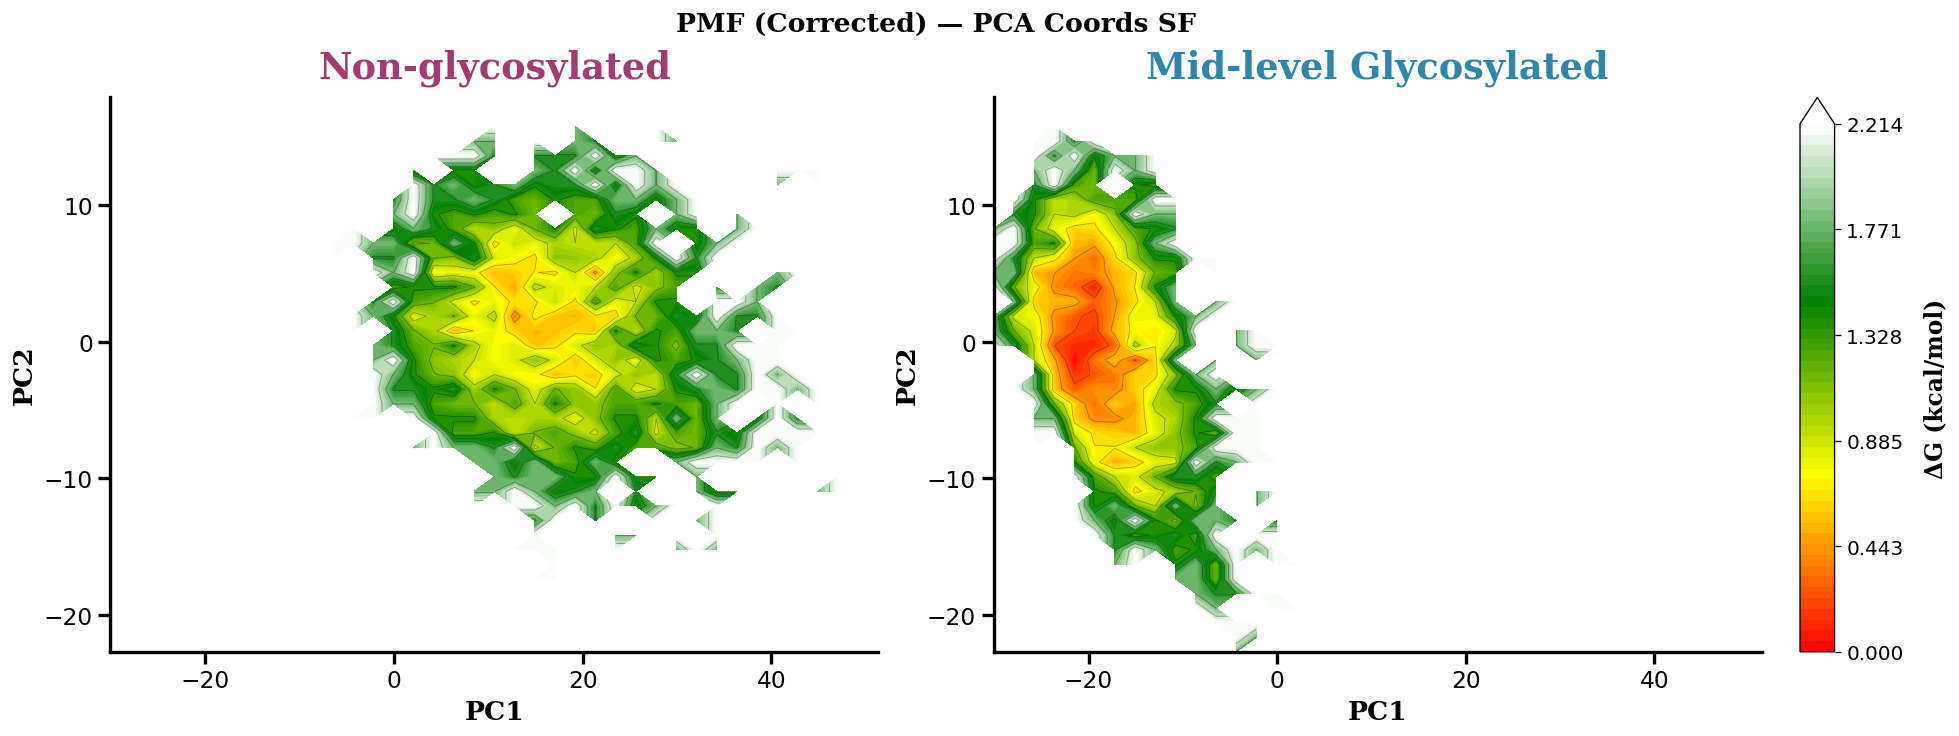

  Saved: /home/computer2/analysis_simulations/analysis/pmf_plots_corrected/pmf_corrected_pca_coords_sf.png


In [3]:
make_pmf_figure(
    dat_file = base + 'pca_coords_sf.dat',
    title    = 'PMF (Corrected) — PCA Coords SF',
    outpath  = os.path.join(output_dir, 'pmf_corrected_pca_coords_sf.png')
)

## Figure — Combined PMF (Glycosylated and Non-glycosylated on same axes)

  2381 glycans  |  2381 noglycans


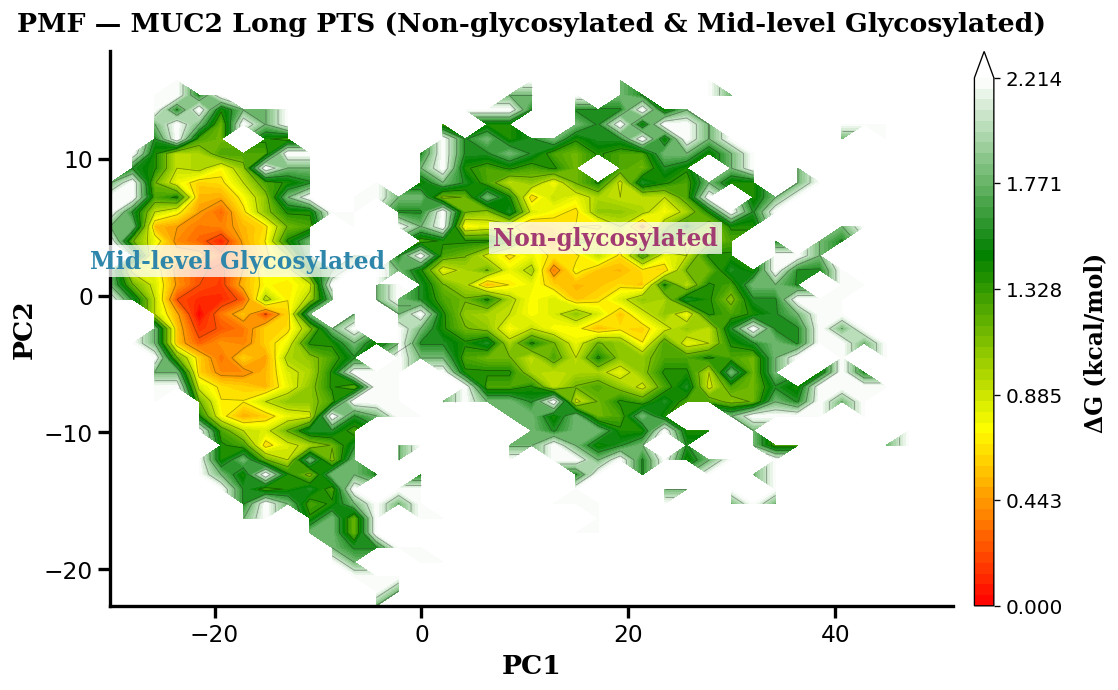

  Saved: /home/computer2/analysis_simulations/analysis/pmf_plots_corrected/pmf_corrected_combined.png


In [4]:
def make_pmf_combined(dat_file, title, outpath):
    """Both systems overlaid on the same axes — shared bins and colour scale."""
    pc1, pc2, labels = load_dat(dat_file)
    gly = labels == 'glycans'
    nog = labels == 'noglycans'
    print(f'  {gly.sum()} glycans  |  {nog.sum()} noglycans')

    xmin = min(pc1[gly].min(), pc1[nog].min())
    xmax = max(pc1[gly].max(), pc1[nog].max())
    ymin = min(pc2[gly].min(), pc2[nog].min())
    ymax = max(pc2[gly].max(), pc2[nog].max())

    bins_x = np.linspace(xmin, xmax, 40)
    bins_y = np.linspace(ymin, ymax, 40)

    H1, xedges, yedges = np.histogram2d(pc1[gly], pc2[gly], bins=(bins_x, bins_y))
    H2, _,      _      = np.histogram2d(pc1[nog], pc2[nog], bins=(bins_x, bins_y))

    def to_pmf(H):
        P = np.where(H == 0, np.nan, H / H.sum())
        return -k * T * np.log(P)

    G1 = to_pmf(H1)
    G2 = to_pmf(H2)

    shared_min = np.nanmin(np.concatenate([G1[~np.isnan(G1)], G2[~np.isnan(G2)]]))
    G1 -= shared_min
    G2 -= shared_min

    vmin = 0.0
    vmax = np.nanpercentile(
        np.concatenate([G1[~np.isnan(G1)], G2[~np.isnan(G2)]]), 98)
    levels = np.linspace(vmin, vmax, 50)
    line_levels = levels[::5]

    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])

    fig = plt.figure(figsize=(9, 6), dpi=120)
    fig.set_facecolor('white')
    ax  = fig.add_axes([0.10, 0.13, 0.78, 0.77])
    cax = fig.add_axes([0.90, 0.13, 0.018, 0.77])

    for G in (G1, G2):
        img = ax.contourf(xc, yc, G.T, cmap=custom_cmap,
                          vmin=vmin, vmax=vmax, levels=levels, extend='max')
        ax.contour(xc, yc, G.T, levels=line_levels,
                   colors='k', linewidths=0.5, alpha=0.35)

    cbar = fig.colorbar(img, cax=cax, extend='max')
    cbar.set_label('ΔG (kcal/mol)', fontsize=14,
                   fontname='DejaVu Serif', fontweight='bold', labelpad=12)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks(np.linspace(vmin, vmax, 6))

    cx_gly = pc1[gly].mean();  cy_gly = pc2[gly].mean()
    cx_nog = pc1[nog].mean();  cy_nog = pc2[nog].mean()
    y_span = (ymax - ymin)
    for cx, cy, lbl, clr in [
        (cx_nog, cy_nog, 'Non-glycosylated',      CLR_NOG),
        (cx_gly, cy_gly, 'Mid-level Glycosylated', CLR_GLY),
    ]:
        ax.text(cx, cy + 0.06 * y_span, lbl,
                fontsize=14, fontname='DejaVu Serif', fontweight='bold',
                color=clr, ha='center', va='bottom',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.75, pad=2.5))

    ax.set_xlabel('PC1', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('PC2', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
    ax.set_title(title, fontsize=16,
                 fontname='DejaVu Serif', fontweight='bold', pad=12)
    _style_ax(ax)

    plt.savefig(outpath, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'  Saved: {outpath}')


make_pmf_combined(
    dat_file = base + 'pca_coords_sf.dat',
    title    = 'PMF — MUC2 Long PTS (Non-glycosylated & Mid-level Glycosylated)',
    outpath  = os.path.join(output_dir, 'pmf_corrected_combined.png')
)

## Three-System PMF (Glycosylated | Non-glycosylated | Ext. Glycosylated)

  2381 noglycans | 2381 glycans | 2381 ext_glycans


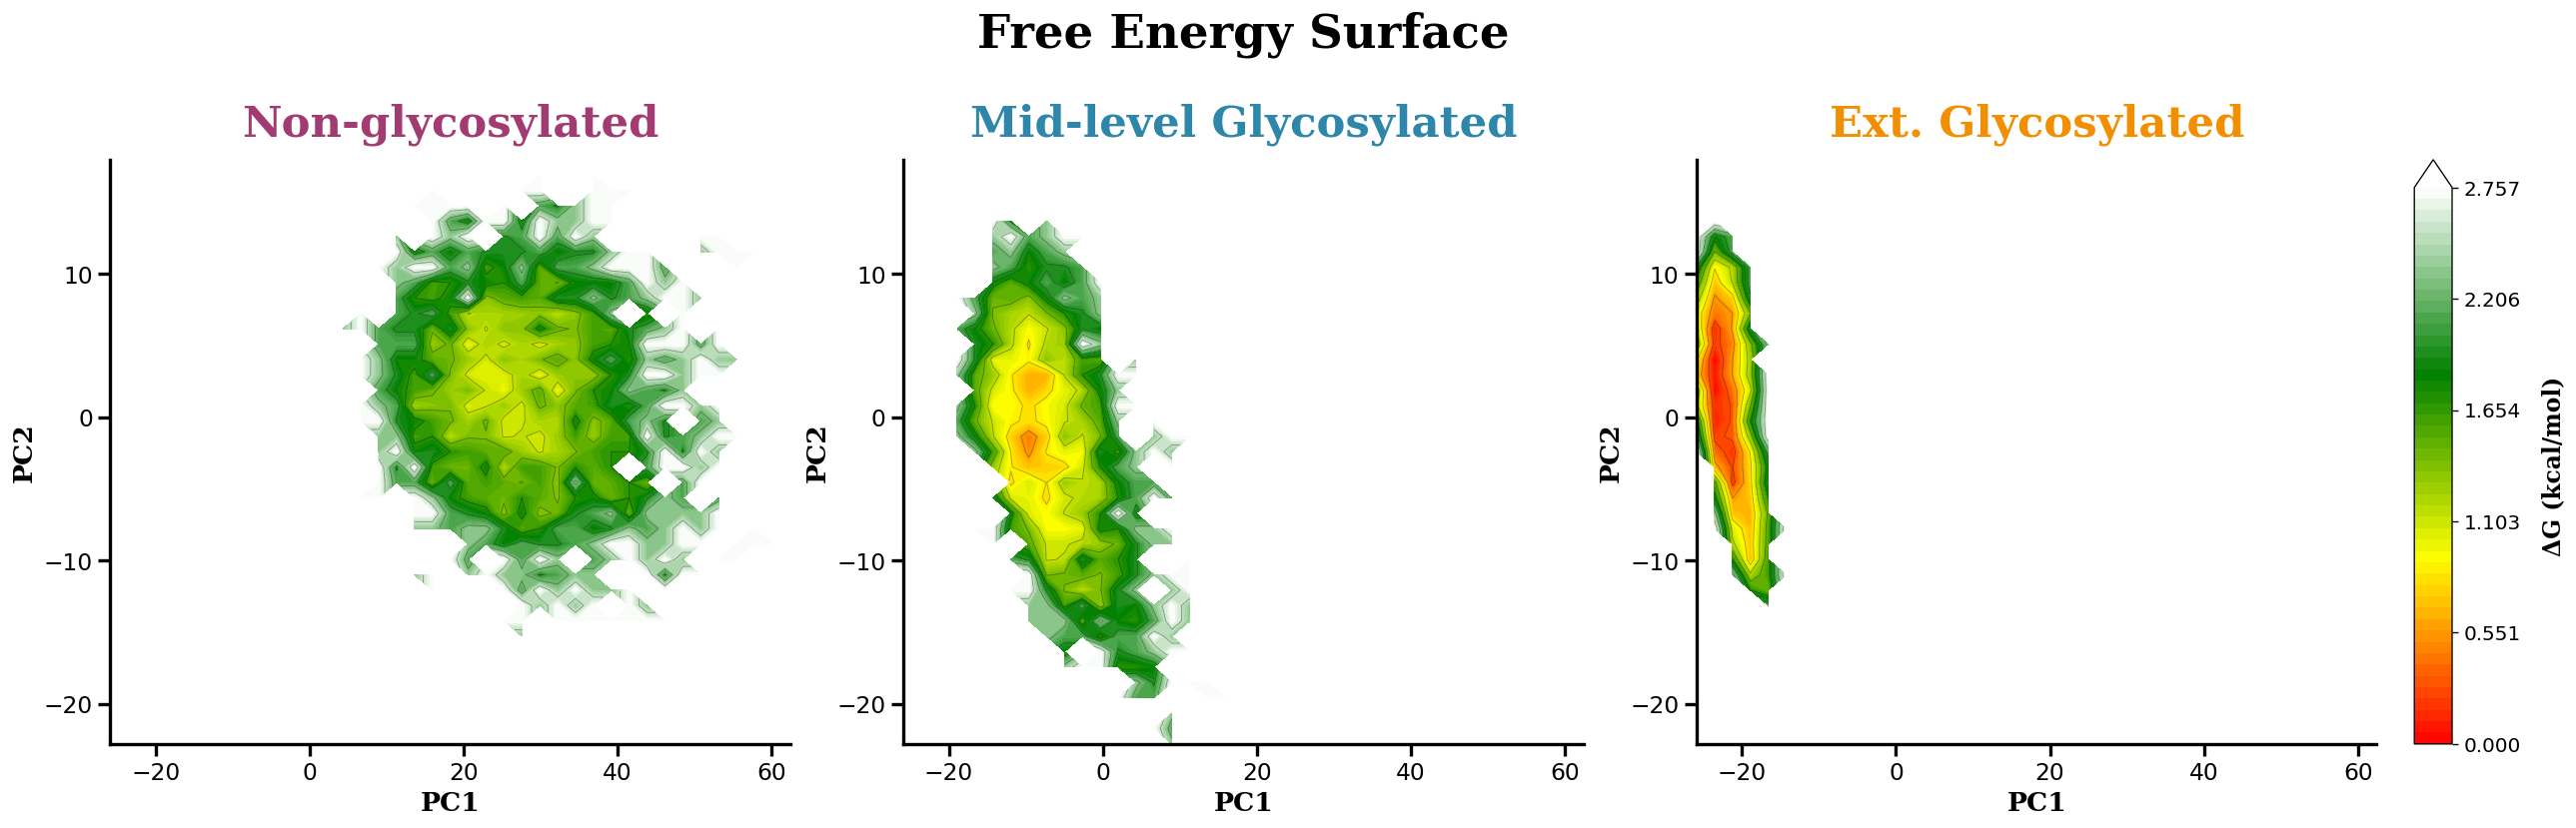

  Saved: /home/computer2/analysis_simulations/analysis/pmf_plots_corrected/pmf_3sys_individual.png


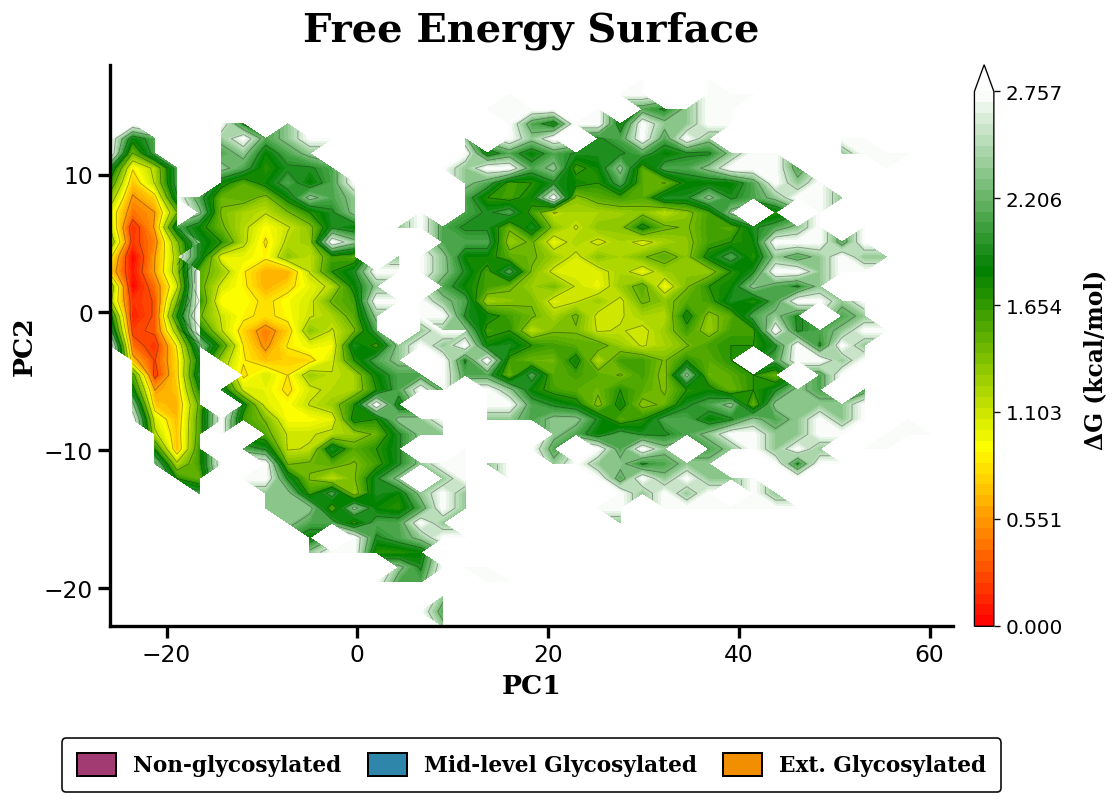

  Saved: /home/computer2/analysis_simulations/analysis/pmf_plots_corrected/pmf_3sys_combined.png


In [5]:
import matplotlib.patches as mpatches

CLR_EXT = "#F18F01"

BASE_3SYS = "/home/computer2/analysis_simulations/analysis/physical_variables/pca_threesystems/"

def load_dat_3sys(filepath):
    d   = np.genfromtxt(filepath, comments='#', dtype=None,
                        encoding='utf-8', names=['pc1', 'pc2', 'system'])
    pc1 = d['pc1'].astype(float)
    pc2 = d['pc2'].astype(float)
    sys = np.array([s.strip() for s in d['system']])
    return pc1, pc2, sys


def make_pmf_3sys_individual(dat_file, title, outpath):
    pc1, pc2, labels = load_dat_3sys(dat_file)
    gly = labels == 'glycans'
    nog = labels == 'noglycans'
    ext = labels == 'ext_glycans'
    print(f'  {nog.sum()} noglycans | {gly.sum()} glycans | {ext.sum()} ext_glycans')

    xmin = pc1.min(); xmax = pc1.max()
    ymin = pc2.min(); ymax = pc2.max()
    bins_x = np.linspace(xmin, xmax, 40)
    bins_y = np.linspace(ymin, ymax, 40)

    def to_pmf(mask):
        H, xedges, yedges = np.histogram2d(pc1[mask], pc2[mask],
                                            bins=(bins_x, bins_y))
        P = np.where(H == 0, np.nan, H / H.sum())
        return -k * T * np.log(P), xedges, yedges

    G_nog, xedges, yedges = to_pmf(nog)
    G_gly, _,      _      = to_pmf(gly)
    G_ext, _,      _      = to_pmf(ext)

    all_vals = np.concatenate([v[~np.isnan(v)] for v in (G_nog, G_gly, G_ext)])
    shared_min = all_vals.min()
    G_nog -= shared_min; G_gly -= shared_min; G_ext -= shared_min

    vmin = 0.0
    vmax = np.nanpercentile(np.concatenate([G_nog[~np.isnan(G_nog)],
                                             G_gly[~np.isnan(G_gly)],
                                             G_ext[~np.isnan(G_ext)]]), 98)
    levels     = np.linspace(vmin, vmax, 50)
    line_levels = levels[::5]
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])

    fig = plt.figure(figsize=(21, 6.5), dpi=120)
    fig.set_facecolor('white')
    ax1 = fig.add_axes([0.05,  0.10, 0.27, 0.75])
    ax2 = fig.add_axes([0.365, 0.10, 0.27, 0.75])
    ax3 = fig.add_axes([0.68,  0.10, 0.27, 0.75])
    cax = fig.add_axes([0.965, 0.10, 0.015, 0.75])

    # Canonical order: Non-glycosylated → Mid-level Glycosylated → Ext. Glycosylated
    for ax, G, ttl, clr in [
        (ax1, G_nog, 'Non-glycosylated',      CLR_NOG),
        (ax2, G_gly, 'Mid-level Glycosylated', CLR_GLY),
        (ax3, G_ext, 'Ext. Glycosylated',      CLR_EXT),
    ]:
        img = ax.contourf(xc, yc, G.T, cmap=custom_cmap,
                          vmin=vmin, vmax=vmax, levels=levels, extend='max')
        ax.contour(xc, yc, G.T, levels=line_levels,
                   colors='k', linewidths=0.5, alpha=0.35)
        ax.set_title(ttl, fontsize=26, fontname='DejaVu Serif',
                     fontweight='bold', color=clr, pad=14)
        ax.set_xlabel('PC1', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
        ax.set_ylabel('PC2', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
        ax.set_facecolor('white')
        ax.spines['top'].set_visible(False);  ax.spines['right'].set_visible(False)
        ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
        ax.tick_params(axis='both', which='major', labelsize=14,
                       length=7, width=2.0, direction='out', colors='black')
        ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
        ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

    cbar = fig.colorbar(img, cax=cax, extend='max')
    cbar.set_label('ΔG (kcal/mol)', fontsize=14,
                   fontname='DejaVu Serif', fontweight='bold', labelpad=12)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks(np.linspace(vmin, vmax, 6))

    fig.suptitle(title, fontsize=28,
                 fontname='DejaVu Serif', fontweight='bold', y=1.04)
    plt.savefig(outpath, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'  Saved: {outpath}')


def make_pmf_3sys_combined(dat_file, title, outpath):
    """All three systems overlaid — colour-coded rectangle legend below the title."""
    pc1, pc2, labels = load_dat_3sys(dat_file)
    gly = labels == 'glycans'
    nog = labels == 'noglycans'
    ext = labels == 'ext_glycans'

    xmin = pc1.min(); xmax = pc1.max()
    ymin = pc2.min(); ymax = pc2.max()
    bins_x = np.linspace(xmin, xmax, 40)
    bins_y = np.linspace(ymin, ymax, 40)

    def to_pmf(mask):
        H, xedges, yedges = np.histogram2d(pc1[mask], pc2[mask],
                                            bins=(bins_x, bins_y))
        P = np.where(H == 0, np.nan, H / H.sum())
        return -k * T * np.log(P), xedges, yedges

    G_nog, xedges, yedges = to_pmf(nog)
    G_gly, _,      _      = to_pmf(gly)
    G_ext, _,      _      = to_pmf(ext)

    all_vals = np.concatenate([v[~np.isnan(v)] for v in (G_nog, G_gly, G_ext)])
    shared_min = all_vals.min()
    G_nog -= shared_min; G_gly -= shared_min; G_ext -= shared_min

    vmin = 0.0
    vmax = np.nanpercentile(np.concatenate([G_nog[~np.isnan(G_nog)],
                                             G_gly[~np.isnan(G_gly)],
                                             G_ext[~np.isnan(G_ext)]]), 98)
    levels     = np.linspace(vmin, vmax, 50)
    line_levels = levels[::5]
    xc = 0.5 * (xedges[:-1] + xedges[1:])
    yc = 0.5 * (yedges[:-1] + yedges[1:])

    fig = plt.figure(figsize=(9, 6.5), dpi=120)
    fig.set_facecolor('white')
    ax  = fig.add_axes([0.10, 0.10, 0.78, 0.72])
    cax = fig.add_axes([0.90, 0.10, 0.018, 0.72])

    for G in (G_nog, G_gly, G_ext):
        img = ax.contourf(xc, yc, G.T, cmap=custom_cmap,
                          vmin=vmin, vmax=vmax, levels=levels, extend='max')
        ax.contour(xc, yc, G.T, levels=line_levels,
                   colors='k', linewidths=0.5, alpha=0.35)

    cbar = fig.colorbar(img, cax=cax, extend='max')
    cbar.set_label('ΔG (kcal/mol)', fontsize=14,
                   fontname='DejaVu Serif', fontweight='bold', labelpad=12)
    cbar.ax.tick_params(labelsize=12)
    cbar.set_ticks(np.linspace(vmin, vmax, 6))

    # Colour-coded rectangle legend — canonical order
    legend_patches = [
        mpatches.Patch(facecolor=CLR_NOG, edgecolor='black',
                       linewidth=1.2, label='Non-glycosylated'),
        mpatches.Patch(facecolor=CLR_GLY, edgecolor='black',
                       linewidth=1.2, label='Mid-level Glycosylated'),
        mpatches.Patch(facecolor=CLR_EXT, edgecolor='black',
                       linewidth=1.2, label='Ext. Glycosylated'),
    ]
    ax.legend(
        handles=legend_patches,
        loc='upper center',
        bbox_to_anchor=(0.5, -0.18),
        ncol=3,
        fontsize=13,
        frameon=True,
        framealpha=0.95,
        edgecolor='black',
        handlelength=1.8,
        handleheight=1.2,
        borderpad=0.7,
        columnspacing=1.2,
        prop={'family': 'DejaVu Serif', 'size': 13, 'weight': 'bold'},
    )

    ax.set_xlabel('PC1', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
    ax.set_ylabel('PC2', fontsize=16, fontname='DejaVu Serif', fontweight='bold')
    ax.set_title(title, fontsize=24,
                 fontname='DejaVu Serif', fontweight='bold', pad=14)
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False);  ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(2.0); ax.spines['bottom'].set_linewidth(2.0)
    ax.tick_params(axis='both', which='major', labelsize=14,
                   length=7, width=2.0, direction='out', colors='black')
    ax.xaxis.set_major_locator(ticker.MaxNLocator(5))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(5))

    plt.savefig(outpath, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    print(f'  Saved: {outpath}')


# --- Individual panels ---
make_pmf_3sys_individual(
    dat_file = BASE_3SYS + 'pca_coords_3sys.dat',
    title    = 'Free Energy Surface',
    outpath  = os.path.join(output_dir, 'pmf_3sys_individual.png')
)

# --- Combined on one axes ---
make_pmf_3sys_combined(
    dat_file = BASE_3SYS + 'pca_coords_3sys.dat',
    title    = 'Free Energy Surface',
    outpath  = os.path.join(output_dir, 'pmf_3sys_combined.png')
)